# Week 7 Homework: Lists and Tuples

**Name:** Michael Richtsmeier

**Instructions**
- Complete each problem in the code cell below it. Write your pseudocode first, in the `'''` block.
- Replace every `pass` with your own code. Don't change the function names.
- Many problems end with **test lines**. Run the cell: if your code is correct, it prints `✅`. If not, you get an `AssertionError`.
- Before you submit, go to **Kernel → Restart & Run All** and make sure every cell runs without errors.

| Part | Topic                                   | Points |
|------|-----------------------------------------|--------|
| A    | List basics, indexing, slicing           | 20     |
| B    | List methods and processing              | 25     |
| C    | List comprehensions                       | 15     |
| D    | Files and lists                            | 10     |
| E    | 2D lists                                   | 15     |
| F    | Tuples                                     | 5      |
| G    | Plotting with matplotlib                   | 10     |
|      | **Total**                                  | **100** |

---
## Part A: List Basics, Indexing and Slicing (20 pts)

**A1. Coffee Shop Menu (5 pts)**

1. Create a list called `menu` with these items: `"latte"`, `"mocha"`, `"espresso"`, `"cold brew"`, `"chai"`.
2. Print the first item, the last item (use a **negative** index) and the number of items.
3. Change `"mocha"` to `"cappuccino"` and print the updated list.

In [65]:
'''
Create menu list
print first item, last item, and length
change mocha to cappuccino
print updated list
'''
menu = ["latte", "mocha", "espresso", "cold brew", "chai"]

print(menu[0], menu[-1], len(menu))

menu[1] = 'cappuccino'
print(menu)


latte chai 5
['latte', 'cappuccino', 'espresso', 'cold brew', 'chai']


**A2. Weekly Sales Slices (5 pts)**

`daily_sales` holds a store's sales for 7 days, Monday through Sunday. Use **slicing** to create:
- `weekdays`: Monday through Friday
- `weekend`: Saturday and Sunday
- `midweek`: Tuesday, Wednesday and Thursday

In [66]:
daily_sales = [210, 185, 240, 198, 305, 410, 375]

weekdays = daily_sales[:5]   # replace None with a slice
weekend  = daily_sales[5:]
midweek  = daily_sales[1:4]

print(weekdays, weekend, midweek)

# Tests
assert weekdays == [210, 185, 240, 198, 305]
assert weekend == [410, 375]
assert midweek == [185, 240, 198]
print("✅ A2 passed")

[210, 185, 240, 198, 305] [410, 375] [185, 240, 198]
✅ A2 passed


**A3. Stock Check (5 pts)**

Write a function `in_stock(item, inventory)` that returns the string `"<item> is in stock"` if `item` is in the `inventory` list, and `"<item> is out of stock"` otherwise. Use the `in` operator.

In [67]:
def in_stock(item, inventory):
    if item in inventory:
        return f"{item} is in stock"
    else:
        return f'{item} is out of stock'


inventory = ["laptop", "mouse", "monitor", "keyboard"]
print(in_stock("mouse", inventory))
print(in_stock("webcam", inventory))

# Tests
assert in_stock("mouse", inventory) == "mouse is in stock"
assert in_stock("webcam", inventory) == "webcam is out of stock"
print("✅ A3 passed")

mouse is in stock
webcam is out of stock
✅ A3 passed


**A4. Index Loop (5 pts)**

Use a `for` loop with `range(len(...))` to print each employee with their badge number. The badge number is the **index + 100**.

Expected output:
```
Badge 100: Ana
Badge 101: Ben
Badge 102: Cara
Badge 103: Dev
```

In [68]:
employees = ["Ana", "Ben", "Cara", "Dev"]

for i in range(len(employees)):
    print(f"Badge {i + 100}: {employees[i]}")

Badge 100: Ana
Badge 101: Ben
Badge 102: Cara
Badge 103: Dev


---
## Part B: List Methods and Processing (25 pts)

**B1. Order Queue (10 pts)**

Start with `queue = ["Order 1", "Order 2", "Order 3"]` and do these steps **in order**, printing the list after each one:
1. `append` `"Order 4"`.
2. A VIP order arrives: `insert` `"Order VIP"` at the **front**.
3. `"Order 2"` was cancelled: `remove` it.
4. Serve the first order: `pop(0)` it and print `"Now serving: <order>"`.
5. Print how many orders are still waiting.

In [69]:
'''
Create order queue
Append order 4 and print queue
insert vip order at front and print queue
remove order 2 and print queue
remove first orster and print which order being served
print remaining orders waiting
'''
queue = ["Order 1", "Order 2", "Order 3"]

queue.append("Order 4")
print(queue)

queue.insert(0, "Order VIP")
print(queue)

queue.remove("Order 2")
print(queue)

served_order = queue.pop(0)
print(f"Now Serving: {served_order}")
print(queue)

print(f"Orders waiting: {len(queue)}")


['Order 1', 'Order 2', 'Order 3', 'Order 4']
['Order VIP', 'Order 1', 'Order 2', 'Order 3', 'Order 4']
['Order VIP', 'Order 1', 'Order 3', 'Order 4']
Now Serving: Order VIP
['Order 1', 'Order 3', 'Order 4']
Orders waiting: 3


**B2. Sales Summary Function (10 pts)**

Write a function `sales_summary(sales)` that takes a list of daily sales amounts and **returns a tuple** `(total, average, highest, lowest)`. Round the average to 2 decimals.

Calculate `total` with a **loop and an accumulator**, not `sum()`. You may use `max()` and `min()` for the others.

In [70]:
def sales_summary(sales):
    total = 0

    for amount in sales:
        total += amount

    average = round(total / len(sales), 2)
    highest = max(sales)
    lowest = min(sales)

    return total, average, highest, lowest


week = [210, 185, 240, 198, 305, 410, 375]
total, average, highest, lowest = sales_summary(week)
print(f"Total: ${total}  Average: ${average}  High: ${highest}  Low: ${lowest}")

# Tests
assert sales_summary(week) == (1923, 274.71, 410, 185)
assert sales_summary([10, 20]) == (30, 15.0, 20, 10)
print("✅ B2 passed")

Total: $1923  Average: $274.71  High: $410  Low: $185
✅ B2 passed


**B3. Safe Copy (5 pts)**

The code below has a bug: changing `sale_prices` also changes `regular_prices`. Fix the line marked `# BUG` so that `regular_prices` stays unchanged. In a comment, explain **why** the original line caused the problem.

In [71]:
regular_prices = [20.0, 35.0, 50.0]
sale_prices = regular_prices[:]

for i in range(len(sale_prices)):
    sale_prices[i] = sale_prices[i] * 0.75

print("Regular:", regular_prices)
print("Sale:   ", sale_prices)

# Why did the original line cause a problem?
# Your answer:
# The original assignment made both variables refer to the same list, 
# slicing creates a fully seperate list, so you can change the variables

# Tests
assert regular_prices == [20.0, 35.0, 50.0]
assert sale_prices == [15.0, 26.25, 37.5]
print("✅ B3 passed")

Regular: [20.0, 35.0, 50.0]
Sale:    [15.0, 26.25, 37.5]
✅ B3 passed


---
## Part C: List Comprehensions (15 pts)

Use a **list comprehension** for each part. Each answer should be a single line.

In [72]:
prices = [4.50, 12.00, 8.75, 22.00, 3.25, 15.50]
products = ["notebook", "pen", "backpack", "calculator", "ruler"]

# C1 (5 pts): every price with a $1.00 shipping fee added
with_shipping = [price + 1.00 for price in prices]

# C2 (5 pts): only the prices over $10
premium = [price for price in prices if price > 10]

# C3 (5 pts): every product name in UPPERCASE, keeping only names longer than 5 characters
long_names = [product.upper() for product in products if len(product) > 5]

print(with_shipping)
print(premium)
print(long_names)

# Tests
assert with_shipping == [5.5, 13.0, 9.75, 23.0, 4.25, 16.5]
assert premium == [12.0, 22.0, 15.5]
assert long_names == ["NOTEBOOK", "BACKPACK", "CALCULATOR"]
print("✅ Part C passed")

[5.5, 13.0, 9.75, 23.0, 4.25, 16.5]
[12.0, 22.0, 15.5]
['NOTEBOOK', 'BACKPACK', 'CALCULATOR']
✅ Part C passed


---
## Part D: Files and Lists (10 pts)

Write two functions:
- `save_list(filename, items)` writes each item in `items` to the file, **one per line**.
- `load_numbers(filename)` reads the file back and **returns a list of floats**. Remember to strip the newline characters.

In [73]:
def save_list(filename, items):
    with open(filename, "w") as file:
        for item in items:
            file.write(str(item) + "\n")

def load_numbers(filename):
    numbers = []

    with open(filename,"r") as file:
        for line in file:
            numbers.append(float(line.strip()))

    return numbers


expenses = [45.99, 12.5, 230.0, 8.25]
save_list("expenses.txt", expenses)
loaded = load_numbers("expenses.txt")
print(loaded)
print("Total expenses:", sum(loaded))

# Tests
assert loaded == [45.99, 12.5, 230.0, 8.25]
print("✅ Part D passed")

[45.99, 12.5, 230.0, 8.25]
Total expenses: 296.74
✅ Part D passed


---
## Part E: Two-Dimensional Lists (15 pts)

Each row of `regional_sales` is a sales region and each column is a quarter (Q1–Q4).

In [74]:
regions = ["North", "South", "East", "West"]
regional_sales = [
    [120, 135, 150, 160],   # North
    [ 90, 110, 105, 130],   # South
    [200, 180, 210, 225],   # East
    [ 75,  80,  95, 100],   # West
]

**E1 (3 pts):** Print the East region's Q3 sales by indexing `regional_sales`.

**E2 (6 pts):** Write `region_totals(table)` that returns a list with the total for each row. Use **nested loops**, not `sum()`.

**E3 (6 pts):** Write `quarter_totals(table)` that returns a list with the total for each **column** (quarter).

In [75]:
# E1
print(regional_sales[2][2])

# E2
def region_totals(table):
    totals = []
    for row in table:
        total = 0
        for value in row:
            total += value
        totals.append(total)

    return totals


# E3
def quarter_totals(table):
    totals = []

    for column in range(len(table[0])):
        total = 0
        for row in table:
            total += row[column]
        totals.append(total)
    
    return totals


print(region_totals(regional_sales))
print(quarter_totals(regional_sales))

# Tests
assert region_totals(regional_sales) == [565, 435, 815, 350]
assert quarter_totals(regional_sales) == [485, 505, 560, 615]
print("✅ Part E passed")

210
[565, 435, 815, 350]
[485, 505, 560, 615]
✅ Part E passed


**E4 (bonus +3 pts):** Use your functions and the `regions` list to print the name of the region with the **highest** total sales.

In [76]:
totals = region_totals(regional_sales)

highest = totals.index(max(totals))
print(regions[highest])

East


---
## Part F: Tuples (5 pts)

1. Create a tuple `store_hours` with the values `"8:00 AM"` and `"9:00 PM"`, and print the closing time.
2. Try to change the opening time to `"7:00 AM"`. Catch the error with `try/except` and print a message that explains why it failed.
3. In a comment, give **one** reason a business program might store this data as a tuple instead of a list.

In [77]:
store_hours = ("8:00 AM", "9:00 PM")
print(store_hours[1])

try:
    store_hours[0] = "7: 00 AM"
except TypeError:
    print("The opening time could not be changed because tuples are not mutable")

# A tuple helps protect important documents from accidental changes

9:00 PM
The opening time could not be changed because tuples are not mutable


---
## Part G: Plotting with matplotlib (10 pts)

Using the `regions` list and your `region_totals()` result from Part E:

1. **(5 pts)** Make a **bar chart** of total sales by region. Include a title, x-axis label and y-axis label.
2. **(5 pts)** Make a **line chart** of the quarterly totals from `quarter_totals()`. Label the x-axis ticks `Q1`–`Q4`, and add a title and axis labels.

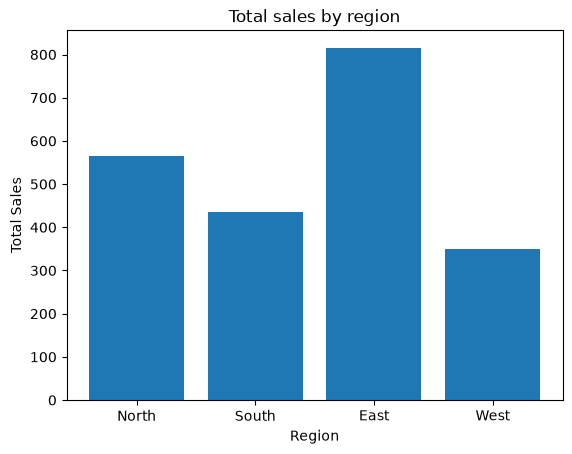

In [78]:
import matplotlib.pyplot as plt
# G1: bar chart
plt.figure()
plt.bar(regions, region_totals(regional_sales))
plt.title("Total sales by region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

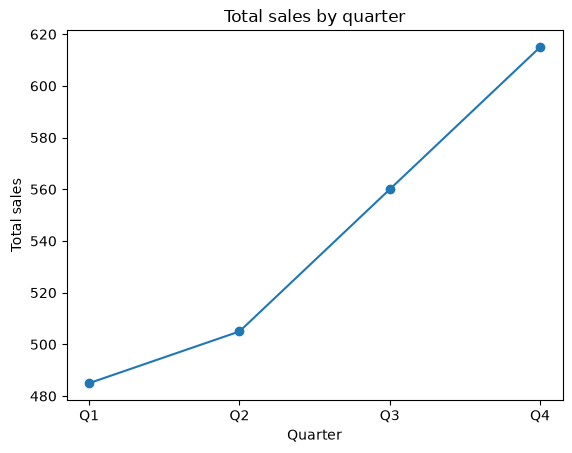

In [79]:
# G2: line chart

quarters = ["Q1", "Q2", "Q3", "Q4"]

plt.figure()
plt.plot(quarters, quarter_totals(regional_sales), marker="o")
plt.title("Total sales by quarter")
plt.xlabel("Quarter")
plt.ylabel("Total sales")
plt.show()

---
### ✅ Before you submit
- [ ] Every `pass` and `None` placeholder is replaced
- [ ] All test cells print ✅
- [ ] **Kernel → Restart & Run All** runs with no errors
- [ ] Both charts appear